![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Sesión 1 · Notebook del estudiante · no calificable</div><div style="font-size:22px;font-weight:700;margin-top:4px">L1.2 · MNIST con seis clasificadores</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Objetivo** | Resolver el problema icónico de clasificación, reconocer dígitos escritos a mano, con los seis clasificadores del programa y compararlos con honestidad. |
| **Duración** | ≈ 90 min con el reto · en el taller de la **Clase 1** (35 min) se completan las celdas `# TODO` de las partes 1 a 5 |
| **Teoría** | Manual M1 §4–§8 · Animaciones A1.5 a A1.10 |
| **Datos icónicos** | **dígitos de scikit-learn** (1 797 imágenes de 8 × 8) y **MNIST** (70 000 imágenes de 28 × 28; LeCun, Cortes y Burges) |
| **Escala realista (reto)** | **Fashion-MNIST** (70 000 fotos de prendas de ropa de Zalando; Xiao y colaboradores, 2017) |

**Partes:** 1 · conocer los datos → 2 · regresión logística multinomial (softmax) → 3 · árbol de decisión → 4 · modelos generativos: LDA, QDA y Naive Bayes → 5 · SVM y k vecinos, y la tabla final → reto con Fashion-MNIST.

MNIST se descarga una sola vez (11 MB) desde el repositorio público de Keras y queda en caché. Para que todo corra en pocos minutos usamos **10 000 imágenes de entrenamiento** y **2 000 de prueba**.

## 0 · Configuración

In [1]:
import gzip
import os
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 2026
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=list(UNIBE.values())), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
CACHE = os.path.expanduser("~/.cache/ml-unibe")
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"


def descargar(nombre):
    """Descarga un archivo del repositorio público de datasets de Keras (una sola vez)."""
    os.makedirs(CACHE, exist_ok=True)
    ruta = os.path.join(CACHE, nombre)
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(URL + nombre, ruta)
    return ruta


def cargar_mnist():
    """MNIST: 60 000 imágenes de entrenamiento y 10 000 de prueba, 28 × 28 píxeles con valores de 0 a 255."""
    d = np.load(descargar("mnist.npz"))
    return d["x_train"], d["y_train"], d["x_test"], d["y_test"]


print(f"scikit-learn {sklearn.__version__} · semilla {SEED}")

scikit-learn 1.6.1 · semilla 2026


## Parte 1 · Conocer los datos

Empezamos con la versión de juguete que trae scikit-learn: 1 797 dígitos de 8 × 8 píxeles. Cada imagen es una **fila** y cada píxel una **variable**: 64 columnas con la intensidad de gris.

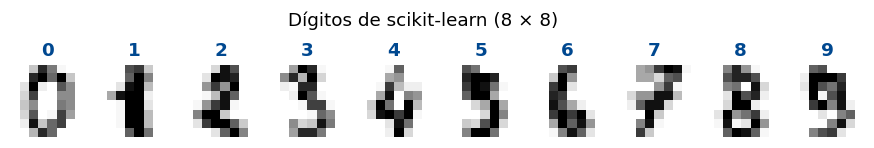

Matriz de datos: (1797, 64) · la primera imagen como fila de 64 números:
 [ 0  0  5 13  9  1  0  0  0  0 13 15 10 15  5  0  0  3 15  2  0 11  8  0
  0  4 12  0  0  8  8  0  0  5  8  0  0  9  8  0  0  4 11  0  1 12  7  0
  0  2 14  5 10 12  0  0  0  0  6 13 10  0  0  0]


In [2]:
from sklearn.datasets import load_digits

dig = load_digits()
fig, axs = plt.subplots(1, 10, figsize=(10, 1.4))
for k, ax in enumerate(axs):
    ax.imshow(dig.images[k], cmap="Greys"); ax.set_title(dig.target[k]); ax.axis("off")
plt.suptitle("Dígitos de scikit-learn (8 × 8)", y=1.08); plt.show()
print("Matriz de datos:", dig.data.shape, "· la primera imagen como fila de 64 números:\n", dig.data[0].astype(int))

Ahora el MNIST de verdad: 28 × 28 = **784 variables** por imagen.

Entrenamiento: (60000, 28, 28) · prueba: (10000, 28, 28)


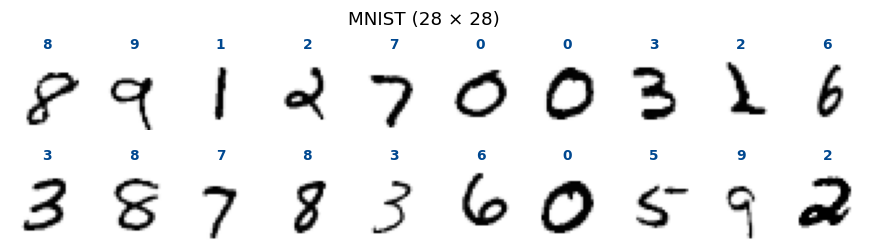

In [3]:
Xtr_full, ytr_full, Xte_full, yte_full = cargar_mnist()
print("Entrenamiento:", Xtr_full.shape, "· prueba:", Xte_full.shape)
rng = np.random.default_rng(SEED)
idx_tr = rng.choice(len(Xtr_full), 10_000, replace=False)
idx_te = rng.choice(len(Xte_full), 2_000, replace=False)
X_tr, y_tr = Xtr_full[idx_tr].reshape(-1, 784) / 255.0, ytr_full[idx_tr]   # escalamos a [0, 1]
X_te, y_te = Xte_full[idx_te].reshape(-1, 784) / 255.0, yte_full[idx_te]
fig, axs = plt.subplots(2, 10, figsize=(10, 2.4))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(X_tr[k].reshape(28, 28), cmap="Greys"); ax.set_title(y_tr[k], fontsize=9); ax.axis("off")
plt.suptitle("MNIST (28 × 28)", y=1.02); plt.show()

**Tu turno.** ¿Están balanceadas las clases? Calcula la proporción de cada dígito en `y_tr` y el **baseline**: la exactitud en la prueba de predecir siempre el dígito más frecuente del entrenamiento.

In [5]:
# TODO: calcula la proporción por dígito (np.bincount) y la exactitud del baseline en la prueba.
prop = np.bincount(y_tr) / len(y_tr)
mas_frecuente = np.argmax(np.bincount(y_tr))
acc_base = np.mean(y_te == mas_frecuente)
print("Proporciones:", prop.round(3), "· más frecuente:", mas_frecuente, f"· baseline = {acc_base:.3f}")
assert 0.08 < acc_base < 0.14, "Con 10 clases casi balanceadas, el baseline ronda el 10–12 %."

Proporciones: [0.097 0.111 0.092 0.102 0.095 0.09  0.102 0.108 0.098 0.104] · más frecuente: 1 · baseline = 0.122


Para comparar los seis modelos guardamos su exactitud y su tiempo en una tabla.

In [6]:
resultados = []


def evaluar(nombre, modelo):
    t0 = time.perf_counter(); modelo.fit(X_tr, y_tr); t1 = time.perf_counter()
    acc = modelo.score(X_te, y_te); t2 = time.perf_counter()
    resultados.append({"modelo": nombre, "exactitud": acc, "entrenar (s)": t1 - t0, "predecir (s)": t2 - t1})
    print(f"{nombre:<34} exactitud = {acc:.3f} · entrenar {t1 - t0:5.1f} s · predecir {t2 - t1:5.2f} s")
    return modelo

## Parte 2 · Regresión logística multinomial (softmax)

Diez puntajes, uno por dígito, convertidos en probabilidades con softmax (M1 §4). Cada clase tiene un vector de 784 pesos: **uno por píxel**.

Logística multinomial (softmax)    exactitud = 0.912 · entrenar  12.4 s · predecir  0.02 s


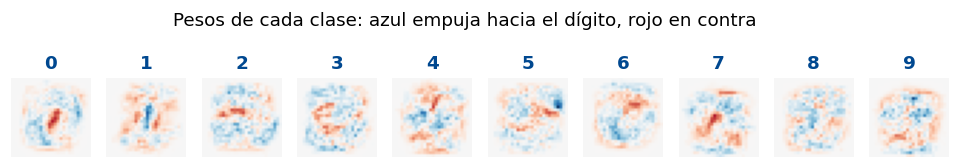

In [7]:
from sklearn.linear_model import LogisticRegression

softmax = evaluar("Logística multinomial (softmax)", LogisticRegression(max_iter=300, C=0.1))
fig, axs = plt.subplots(1, 10, figsize=(11, 1.6))
lim = np.abs(softmax.coef_).max()
for k, ax in enumerate(axs):
    ax.imshow(softmax.coef_[k].reshape(28, 28), cmap="RdBu", vmin=-lim, vmax=lim); ax.set_title(k); ax.axis("off")
plt.suptitle("Pesos de cada clase: azul empuja hacia el dígito, rojo en contra", y=1.1); plt.show()

**Tu turno.** Toma la primera imagen de la prueba y muestra sus 10 probabilidades. ¿Suman 1? ¿Qué tan seguro está el modelo?

In [9]:
# TODO: calcula las 10 probabilidades de X_te[:1] con softmax.predict_proba.
p0 = softmax.predict_proba(X_te[:1])[0]
print("Dígito real:", y_te[0], "· probabilidades:", p0.round(3), "· suma:", round(float(p0.sum()), 6))
assert abs(p0.sum() - 1) < 1e-9

Dígito real: 2 · probabilidades: [0.    0.037 0.867 0.06  0.    0.    0.004 0.    0.031 0.001] · suma: 1.0


## Parte 3 · Árbol de decisión

Un árbol pregunta por píxeles: «¿el píxel 350 es más oscuro que 0.3?». Veamos cómo cambia con la profundidad.

In [10]:
from sklearn.tree import DecisionTreeClassifier

for prof in (2, 5, 10, 20):
    t = DecisionTreeClassifier(max_depth=prof, random_state=SEED).fit(X_tr, y_tr)
    print(f"profundidad {prof:>2}: entrenamiento = {t.score(X_tr, y_tr):.3f} · prueba = {t.score(X_te, y_te):.3f} · hojas = {t.get_n_leaves()}")

profundidad  2: entrenamiento = 0.348 · prueba = 0.358 · hojas = 4
profundidad  5: entrenamiento = 0.693 · prueba = 0.689 · hojas = 32
profundidad 10: entrenamiento = 0.933 · prueba = 0.821 · hojas = 555
profundidad 20: entrenamiento = 0.998 · prueba = 0.823 · hojas = 1010


**Tu turno.** Elige la profundidad que te parezca mejor según lo anterior y evalúa ese árbol con `evaluar`. (Ojo: elegir con la prueba es una pequeña trampa que corregiremos en L1.3 con validación cruzada.)

Árbol de decisión (profundidad 10) exactitud = 0.821 · entrenar   1.9 s · predecir  0.01 s


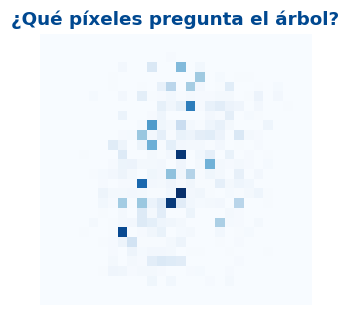

In [12]:
# TODO: evalúa un DecisionTreeClassifier con la profundidad elegida (random_state=SEED).
arbol = evaluar("Árbol de decisión (profundidad 10)", DecisionTreeClassifier(max_depth=10, random_state=SEED))
plt.figure(figsize=(3.2, 3.2))
plt.imshow(arbol.feature_importances_.reshape(28, 28), cmap="Blues"); plt.axis("off")
plt.title("¿Qué píxeles pregunta el árbol?"); plt.show()

## Parte 4 · Modelos generativos: LDA, QDA y Naive Bayes

Estos modelos aprenden **cómo es cada dígito** (una gaussiana por clase) y deciden con la regla de Bayes (M1 §6–§7). Primero en Iris, donde los supuestos son razonables:

In [13]:
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB

Xi, yi = load_iris(return_X_y=True)
for nombre, m in [("LDA", LinearDiscriminantAnalysis()), ("QDA", QuadraticDiscriminantAnalysis()), ("Naive Bayes", GaussianNB())]:
    print(f"Iris · {nombre:<12} exactitud CV = {cross_val_score(m, Xi, yi, cv=5).mean():.3f}")

Iris · LDA          exactitud CV = 0.980
Iris · QDA          exactitud CV = 0.980
Iris · Naive Bayes  exactitud CV = 0.953


Ahora en MNIST. QDA necesita estimar una matriz de 784 × 784 por dígito; muchos píxeles del borde siempre valen 0 y las matrices son singulares, así que la regularizamos con `reg_param`.

In [14]:
lda = evaluar("LDA (covarianza compartida)", LinearDiscriminantAnalysis())
qda = evaluar("QDA regularizada (reg_param=0.5)", QuadraticDiscriminantAnalysis(reg_param=0.5))

LDA (covarianza compartida)        exactitud = 0.868 · entrenar   3.5 s · predecir  0.01 s
QDA regularizada (reg_param=0.5)   exactitud = 0.932 · entrenar   7.4 s · predecir  0.85 s


**Tu turno.** Evalúa Naive Bayes gaussiano. Antes de ejecutar, apuesta: ¿le irá mejor o peor que a LDA? Recuerda que supone que los píxeles son independientes dentro de cada dígito.

In [16]:
# TODO: evalúa GaussianNB() con la función evaluar.
nb = evaluar("Naive Bayes gaussiano", GaussianNB())
assert resultados[-1]["exactitud"] < resultados[-3]["exactitud"], "En MNIST, Naive Bayes debería quedar por debajo de LDA."

Naive Bayes gaussiano              exactitud = 0.603 · entrenar   0.1 s · predecir  0.12 s


Los píxeles vecinos están muy correlacionados: Naive Bayes cuenta varias veces la misma evidencia y se vuelve exageradamente seguro. Mira la confianza media (probabilidad de la clase elegida) de cada modelo:

In [17]:
for nombre, m in [("LDA", lda), ("Naive Bayes", nb)]:
    p = m.predict_proba(X_te).max(axis=1)
    print(f"{nombre:<12} confianza media = {p.mean():.3f} · exactitud = {m.score(X_te, y_te):.3f}")

LDA          confianza media = 0.954 · exactitud = 0.868
Naive Bayes  confianza media = 0.998 · exactitud = 0.603


## Parte 5 · SVM y k vecinos más cercanos

Dos modelos que dependen de distancias. En MNIST todos los píxeles comparten escala (0 a 1), así que no hace falta estandarizar. La SVM con kernel RBF es la más lenta de entrenar; kNN no entrena, pero cada predicción recorre las 10 000 imágenes guardadas.

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

svm = evaluar("SVM con kernel RBF (C=10)", SVC(kernel="rbf", C=10, gamma="scale"))

SVM con kernel RBF (C=10)          exactitud = 0.973 · entrenar  12.1 s · predecir  8.34 s


**Tu turno.** Evalúa kNN con `n_neighbors=3`.

In [20]:
# TODO: evalúa KNeighborsClassifier(n_neighbors=3).
knn = evaluar("k vecinos (k=3)", KNeighborsClassifier(n_neighbors=3))

k vecinos (k=3)                    exactitud = 0.952 · entrenar   0.0 s · predecir  2.04 s


### La tabla final

In [21]:
tabla = pd.DataFrame(resultados).sort_values("exactitud", ascending=False).reset_index(drop=True)
tabla.loc[len(tabla)] = {"modelo": "Baseline (dígito más frecuente)", "exactitud": acc_base, "entrenar (s)": 0.0, "predecir (s)": 0.0}
tabla.round({"exactitud": 3, "entrenar (s)": 1, "predecir (s)": 2})

,modelo,exactitud,entrenar (s),predecir (s)
0,SVM con kernel RBF (C=10),0.973,12.1,8.34
1,k vecinos (k=3),0.952,0.0,2.04
2,QDA regularizada (reg_param=0.5),0.932,7.4,0.85
3,Logística multinomial (softmax),0.912,12.4,0.02
4,LDA (covarianza compartida),0.868,3.5,0.01
5,Árbol de decisión (profundidad 10),0.820,1.9,0.01
6,Naive Bayes gaussiano,0.603,0.1,0.12
7,Baseline (dígito más frecuente),0.122,0.0,0.00


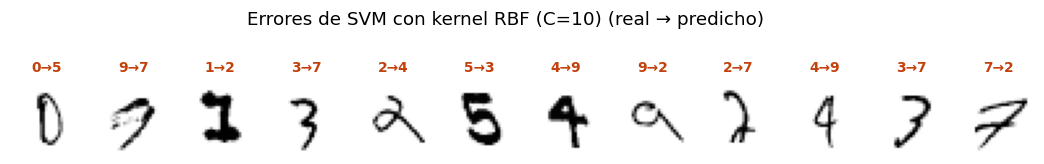

In [22]:
assert tabla.loc[0, "modelo"].startswith(("SVM", "k vecinos")), "Con píxeles crudos, los modelos por distancias suelen ganar."
mejor = svm if tabla.loc[0, "modelo"].startswith("SVM") else knn
pred = mejor.predict(X_te)
errores = np.flatnonzero(pred != y_te)[:12]
fig, axs = plt.subplots(1, len(errores), figsize=(12, 1.6))
for ax, i in zip(axs, errores):
    ax.imshow(X_te[i].reshape(28, 28), cmap="Greys"); ax.set_title(f"{y_te[i]}→{pred[i]}", fontsize=9, color=UNIBE["naranja"]); ax.axis("off")
plt.suptitle(f"Errores de {tabla.loc[0, 'modelo']} (real → predicho)", y=1.1); plt.show()

**Preguntas para la discusión (Clase 1):**

1. ¿Por qué Naive Bayes queda tan atrás en imágenes y, en cambio, funciona bien en Iris?
2. ¿Qué modelo elegirías para una aplicación en un teléfono que debe responder en milisegundos? ¿Y si tuvieras los 60 000 ejemplos?
3. Mira los errores del mejor modelo: ¿los cometería también una persona?

1.- En Iris (Variables poco correlacionadas): Las variables (largo y ancho de sépalos/pétalos) aportan información bastante independiente. El supuesto de Naive Bayes (independencia condicional de las variables dada la clase) se aproxima razonablemente bien.
En Imágenes (Variables altamente correlacionadas): En MNIST, los píxeles vecinos están fuertemente correlacionados (si un píxel es negro, es muy probable que sus vecinos también lo sean). Naive Bayes asume que cada píxel es independiente, por lo que duplica o multiplica la misma evidencia repetidamente. Esto hace que el modelo se vuelva extremadamente seguro de sus predicciones (confianza media del 99.8%) incluso cuando está equivocado, destruyendo su precisión (apenas 60.3%).

2. ¿Qué modelo elegirías para una aplicación en un teléfono que debe responder en milisegundos? ¿Y si tuvieras los 60 000 ejemplos?
En un teléfono (Bajos recursos / Respuesta en milisegundos): Elegiría la Regresión Logística Multinomial (Softmax). Aunque su entrenamiento toma algo de tiempo (12.4 s), la predicción consiste en una simple multiplicación de matrices sumamente rápida (0.02 s).
¿Por qué evitar kNN o SVM en producción?
kNN no requiere entrenamiento, pero para predecir debe calcular la distancia con los 10,000 ejemplos almacenados, tardando 2.04 segundos (¡demasiado lento!). Si tuviéramos los 60,000 ejemplos, este tiempo se multiplicaría por 6, haciendo inviable su uso en tiempo real.
SVM con RBF ofrece la mayor precisión (97.3%), pero su tiempo de predicción (8.34 segundos) es sumamente costoso para un dispositivo móvil porque depende de los vectores de soporte.

3. Mira los errores del mejor modelo (SVM): ¿los cometería también una persona?
Si observamos las imágenes de error:

Muchos de los dígitos están escritos de forma sumamente ambigua o deformada (por ejemplo, un 4 que parece un 9 debido a que el trazo superior está casi cerrado, o un 3 que parece un 7 inclinado).
Sí, una persona también cometería estos errores o al menos dudaría bastante al intentar clasificarlos sin un contexto claro, lo que demuestra que el modelo SVM ha alcanzado un nivel de precisión sumamente cercano al límite de la capacidad humana en este conjunto de datos.

## Reto · Escala realista con Fashion-MNIST

**Fashion-MNIST** tiene el mismo formato que MNIST (28 × 28, 10 clases, 60 000 + 10 000), pero las imágenes son fotos de prendas: camisetas, pantalones, suéteres, vestidos, abrigos, sandalias, camisas, zapatillas, bolsos y botines. Se creó porque MNIST ya era «demasiado fácil». Repite la comparación con tres modelos y mira cuánto cae la exactitud.

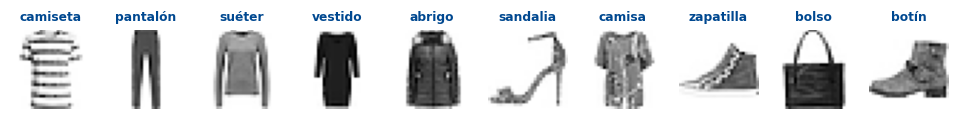

In [23]:
def cargar_fashion():
    """Fashion-MNIST desde el repositorio público de Keras (cuatro archivos en formato IDX comprimido)."""
    def imagenes(nombre):
        with gzip.open(descargar(nombre)) as f:
            return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28, 28)

    def etiquetas(nombre):
        with gzip.open(descargar(nombre)) as f:
            return np.frombuffer(f.read(), np.uint8, offset=8)
    return (imagenes("train-images-idx3-ubyte.gz"), etiquetas("train-labels-idx1-ubyte.gz"),
            imagenes("t10k-images-idx3-ubyte.gz"), etiquetas("t10k-labels-idx1-ubyte.gz"))


PRENDAS = ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "zapatilla", "bolso", "botín"]
Ftr, fytr, Fte, fyte = cargar_fashion()
F_tr, fy_tr = Ftr[idx_tr].reshape(-1, 784) / 255.0, fytr[idx_tr]
F_te, fy_te = Fte[idx_te].reshape(-1, 784) / 255.0, fyte[idx_te]
fig, axs = plt.subplots(1, 10, figsize=(11, 1.6))
for k, ax in enumerate(axs):
    i = int(np.flatnonzero(fy_tr == k)[0])
    ax.imshow(F_tr[i].reshape(28, 28), cmap="Greys"); ax.set_title(PRENDAS[k], fontsize=8); ax.axis("off")
plt.show()

In [25]:
# TODO (reto): entrena softmax, LDA y SVM en Fashion-MNIST y compara su exactitud con la de MNIST.
modelos_reto = [
    ("Logística multinomial (softmax)", LogisticRegression(max_iter=300, C=0.1)),
    ("LDA (covarianza compartida)", LinearDiscriminantAnalysis()),
    ("SVM con kernel RBF (C=10)", SVC(kernel="rbf", C=10, gamma="scale"))
]

for nombre, m in modelos_reto:
    t0 = time.perf_counter()
    m.fit(F_tr, fy_tr)
    t1 = time.perf_counter()
    acc = m.score(F_te, fy_te)
    t2 = time.perf_counter()
    print(f"[Fashion-MNIST] {nombre:<30} exactitud = {acc:.3f} · entrenar {t1 - t0:5.1f} s · predecir {t2 - t1:5.2f} s")

[Fashion-MNIST] Logística multinomial (softmax) exactitud = 0.834 · entrenar  27.2 s · predecir  0.01 s
[Fashion-MNIST] LDA (covarianza compartida)    exactitud = 0.813 · entrenar   2.7 s · predecir  0.01 s
[Fashion-MNIST] SVM con kernel RBF (C=10)      exactitud = 0.874 · entrenar  13.2 s · predecir  9.44 s


## Desafío opcional con IA agéntica · Un séptimo clasificador para MNIST

**Objetivo.** Usar un asistente de IA para sumar un modelo a la comparación de MNIST, verificar que el código hace lo que dice y detectar sus errores.

**Prompt inicial.** Úsalo en la herramienta que prefieras (Claude Code, Codex, Gemini en Colab, ChatGPT…), con este notebook resuelto como contexto. Pide primero un plan y revisa cada paso antes de aprobarlo.

```text
En el notebook resuelto L1.2 (MNIST con seis clasificadores, 10 000 imágenes de entrenamiento y 2 000 de prueba), muéstrame primero un plan. Después agrega un séptimo clasificador que no esté en la tabla (por ejemplo, un bosque aleatorio o la regresión logística sobre 50 componentes principales), evalúalo con la misma función evaluar y la misma muestra, y agrega a la tabla una columna con la exactitud de validación cruzada de 3 pliegues calculada solo con el entrenamiento. No cambies la muestra ni la semilla.
```

**Cómo verificar el resultado**

- El nuevo modelo usa exactamente las mismas X_tr, y_tr, X_te, y_te que los demás.
- La validación cruzada se calcula sin la prueba.
- Puedes explicar con tus palabras por qué el nuevo modelo queda por encima o por debajo de la SVM.

**Declara el uso de IA** (como pide el sílabo): herramienta, prompts relevantes, qué verificaste tú y qué corregiste. El desafío es opcional y no se califica; lo que cuenta es que puedas explicar cada decisión.

# 1. Plan de trabajo
Antes de modificar el notebook, presenta este plan:
1. Revisar los seis clasificadores existentes y la función evaluar.
2. Identificar las variables de entrenamiento y prueba (X_tr, y_tr, X_te, y_te).
3. Crear un séptimo clasificador: Random Forest.
4. Evaluarlo utilizando exactamente los mismos datos de prueba y la función evaluar.
5. Calcular validación cruzada de 3 pliegues utilizando exclusivamente los datos de entrenamiento.
6. Agregar los resultados a la tabla comparativa sin eliminar los modelos anteriores.
7. Comparar el resultado de Random Forest con SVM.
8. Verificar que no se hayan cambiado la muestra ni la semilla aleatoria.

##2. Código para agregar al notebook
Coloca este código después de la evaluación de los seis clasificadores existentes.

In [27]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluar(nombre, modelo, X_tr, y_tr, X_te, y_te):
    # Entrenamiento
    modelo.fit(X_tr, y_tr)

    # Predicciones
    y_pred = modelo.predict(X_te)

    # Exactitud
    exactitud = accuracy_score(y_te, y_pred)

    print(f"\nModelo: {nombre}")
    print(f"Exactitud: {exactitud:.4f}")
    print("\nReporte de clasificación:")
    print(classification_report(y_te, y_pred))

    return {
        "modelo": nombre,
        "exactitud": exactitud,
        "matriz_confusion": confusion_matrix(y_te, y_pred)
    }


In [28]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Séptimo clasificador: Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Evaluación
resultado_rf = evaluar(
    "Random Forest",
    modelo_rf,
    X_tr,
    y_tr,
    X_te,
    y_te
)

# Validación cruzada de 3 pliegues
cv_rf = cross_val_score(
    modelo_rf,
    X_tr,
    y_tr,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

exactitud_cv_rf = cv_rf.mean()

print("Exactitud por pliegue:", cv_rf)
print("Exactitud promedio CV:", exactitud_cv_rf)



Modelo: Random Forest
Exactitud: 0.9535

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       203
           1       0.98      0.98      0.98       244
           2       0.96      0.92      0.94       190
           3       0.91      0.94      0.92       204
           4       0.95      0.96      0.95       194
           5       0.96      0.90      0.93       177
           6       0.96      0.99      0.97       177
           7       0.95      0.93      0.94       209
           8       0.93      0.95      0.94       179
           9       0.96      0.96      0.96       223

    accuracy                           0.95      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.95      0.95      0.95      2000

Exactitud por pliegue: [0.94631074 0.93909391 0.94269427]
Exactitud promedio CV: 0.9426996388901037


##3. Agregar los resultados a la tabla
Si tu tabla original es un DataFrame de pandas llamado resultados, puedes incorporar el nuevo modelo así:

In [30]:
import pandas as pd

# Convertir la lista en DataFrame
resultados = pd.DataFrame(resultados)

# Agregar el séptimo clasificador
resultados.loc[len(resultados)] = {
    "modelo": "Random Forest",
    "exactitud": resultado_rf["exactitud"],
    "CV Accuracy": exactitud_cv_rf
}

display(resultados)

,modelo,exactitud,entrenar (s),predecir (s)
0,Logística multinomial (softmax),0.9120,12.418865,0.015615
1,Árbol de decisión (profundidad 10),0.8205,1.945649,0.005372
2,LDA (covarianza compartida),0.8675,3.492316,0.011421
3,QDA regularizada (reg_param=0.5),0.9320,7.360831,0.846172
4,Naive Bayes gaussiano,0.6030,0.133506,0.118316
5,SVM con kernel RBF (C=10),0.9730,12.148600,8.337063
6,k vecinos (k=3),0.9515,0.021124,2.040965
7,Random Forest,0.9535,NaN,NaN


### Declaración de uso de Inteligencia Artificial

**Herramienta utilizada:** ChatGPT.

**Uso de la herramienta:** Se utilizó inteligencia artificial como asistente para proponer un plan de implementación de un séptimo clasificador para el conjunto de datos MNIST. Se solicitó incorporar un modelo Random Forest, evaluarlo con la misma función utilizada en los clasificadores anteriores y calcular su exactitud mediante validación cruzada de tres pliegues.

**Prompts relevantes:**
- Solicitar un plan antes de realizar modificaciones al notebook.
- Agregar un clasificador Random Forest utilizando los mismos datos de entrenamiento y prueba.
- Calcular la validación cruzada exclusivamente con los datos de entrenamiento.
- Incorporar los resultados a la tabla comparativa.

**Verificaciones realizadas por el estudiante:**
- Se comprobó que se utilizaran las mismas muestras de entrenamiento y prueba.
- Se verificó que la validación cruzada no utilizara los datos de prueba.
- Se revisó que se conservara la semilla original.
- Se compararon los resultados de Random Forest con los obtenidos por SVM.

**Correcciones realizadas:** Se revisó el código propuesto para asegurar que respetara la estructura del notebook original y que no modificara los datos ni la evaluación de los clasificadores existentes.

**Conclusión:** La inteligencia artificial se utilizó como herramienta de apoyo. Las decisiones de implementación, revisión del código e interpretación de los resultados fueron responsabilidad del estudiante.